In [1]:
%matplotlib inline

import pandas as pd
import matplotlib as mpl
import numpy as np

import matplotlib.pyplot as plt
import plotly.express as px
from plotly.offline import iplot, plot

import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# Regression Models
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import BaggingRegressor

# Classifer Models
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier

# To visualize individual decision trees
from sklearn import tree
from sklearn.tree import export_text

In [2]:
df = pd.read_csv("HR-Employee-Attrition.csv")
df = pd.DataFrame(df, dtype=object)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   object
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   object
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   object
 6   Education                 1470 non-null   object
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   object
 9   EmployeeNumber            1470 non-null   object
 10  EnvironmentSatisfaction   1470 non-null   object
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   object
 13  JobInvolvement            1470 non-null   object
 14  JobLevel                

# Count the null value

In [3]:
df.isna().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [4]:
df.sample(10)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
673,33,No,Travel_Rarely,1198,Research & Development,1,4,Other,1,939,...,2,80,0,6,1,3,3,2,0,2
119,43,No,Travel_Frequently,394,Sales,26,2,Life Sciences,1,158,...,4,80,2,25,3,4,25,12,4,12
1180,36,No,Travel_Rarely,311,Research & Development,7,3,Life Sciences,1,1659,...,3,80,0,15,4,3,4,3,1,3
939,32,Yes,Travel_Rarely,1089,Research & Development,7,2,Life Sciences,1,1309,...,1,80,1,10,3,3,10,4,1,1
1294,41,No,Travel_Rarely,447,Research & Development,5,3,Life Sciences,1,1814,...,1,80,0,11,3,1,3,2,1,2
1410,40,No,Travel_Rarely,444,Sales,2,2,Marketing,1,1986,...,3,80,1,15,4,3,11,8,5,10
476,24,No,Travel_Rarely,823,Research & Development,17,2,Other,1,643,...,4,80,1,1,2,3,1,0,0,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
521,27,No,Travel_Frequently,1410,Sales,3,1,Medical,1,714,...,2,80,2,6,3,3,6,5,0,4
1058,34,Yes,Travel_Rarely,790,Sales,24,4,Medical,1,1489,...,3,80,0,16,2,4,15,9,10,10


In [5]:
df.dtypes

Age                         object
Attrition                   object
BusinessTravel              object
DailyRate                   object
Department                  object
DistanceFromHome            object
Education                   object
EducationField              object
EmployeeCount               object
EmployeeNumber              object
EnvironmentSatisfaction     object
Gender                      object
HourlyRate                  object
JobInvolvement              object
JobLevel                    object
JobRole                     object
JobSatisfaction             object
MaritalStatus               object
MonthlyIncome               object
MonthlyRate                 object
NumCompaniesWorked          object
Over18                      object
OverTime                    object
PercentSalaryHike           object
PerformanceRating           object
RelationshipSatisfaction    object
StandardHours               object
StockOptionLevel            object
TotalWorkingYears   

In [6]:
df.duplicated().sum()

0

In [7]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [8]:
df.tail()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,...,1,80,0,6,3,4,4,3,1,2


In [9]:
df.shape

(1470, 35)

# Cleaning the data

In [10]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')

In [11]:
showtype = df['JobRole'].value_counts().reset_index()
showtype

,JobRole,count
0,Sales Executive,326
1,Research Scientist,292
2,Laboratory Technician,259
3,Manufacturing Director,145
4,Healthcare Representative,131
5,Manager,102
6,Sales Representative,83
7,Research Director,80
8,Human Resources,52


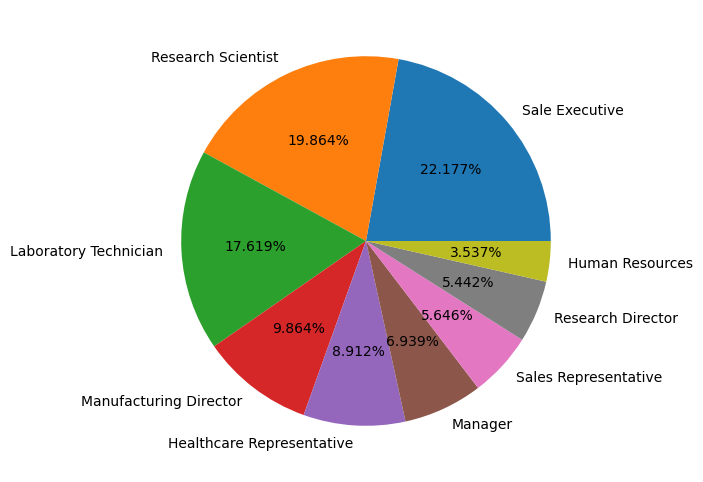

In [12]:
plt.figure(figsize=(20,6))
plt.pie(showtype['count'],labels=['Sale Executive','Research Scientist', 'Laboratory Technician', 'Manufacturing Director', 'Healthcare Representative', 'Manager', 'Sales Representative', 'Research Director', 'Human Resources'],autopct='%1.3f%%')
plt.show()

# Education Column

In [13]:
df["EducationField"].value_counts()

EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64

In [14]:
df["EducationField"].nunique()

6

In [15]:
edu = df['EducationField'].value_counts().reset_index().sort_values(by='count',ascending = False)
edu

,EducationField,count
0,Life Sciences,606
1,Medical,464
2,Marketing,159
3,Technical Degree,132
4,Other,82
5,Human Resources,27


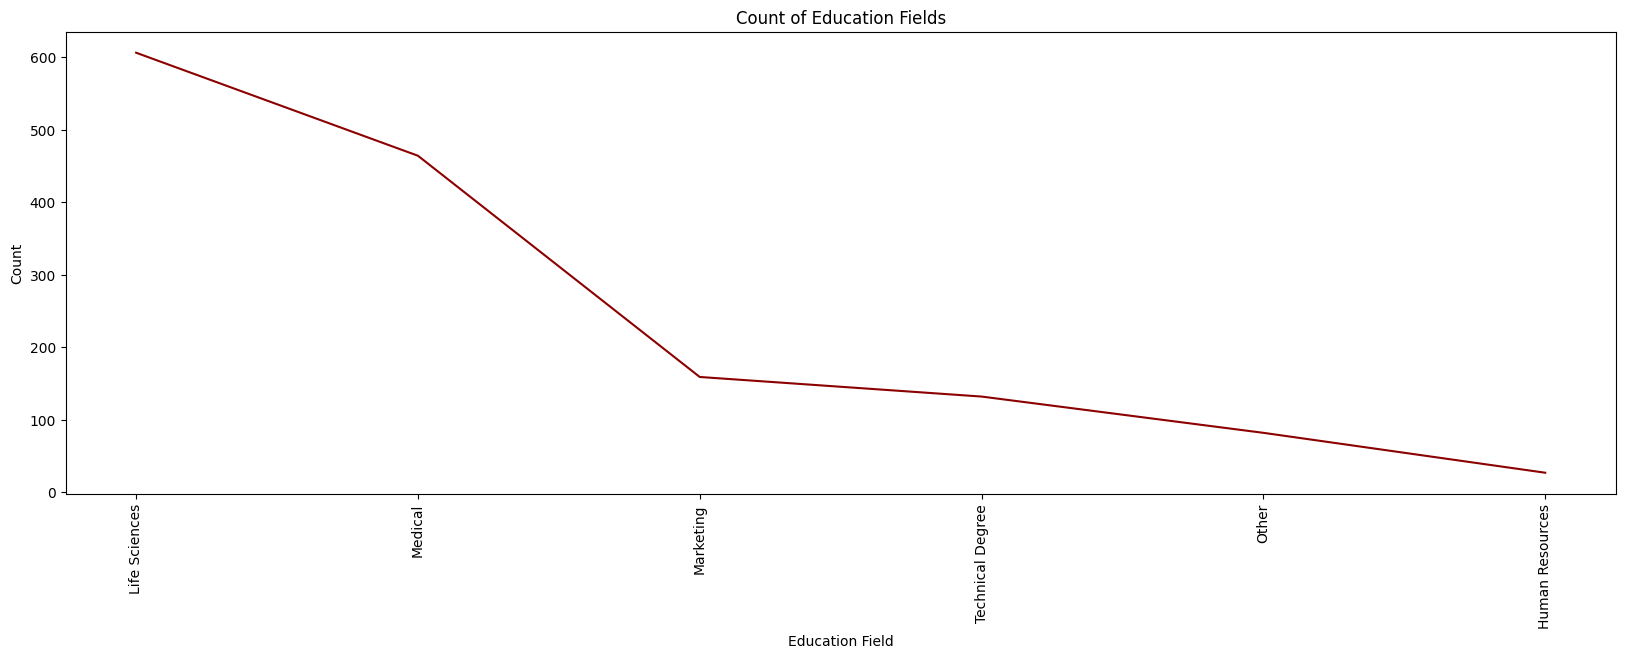

In [16]:
plt.figure(figsize=(20,6))
plt.plot(edu['EducationField'],edu['count'],color='darkred')
plt.xticks(rotation=90)
plt.xlabel('Education Field')
plt.ylabel('Count')
plt.title('Count of Education Fields')
plt.show()

Text(0, 0.5, 'No of Employee')

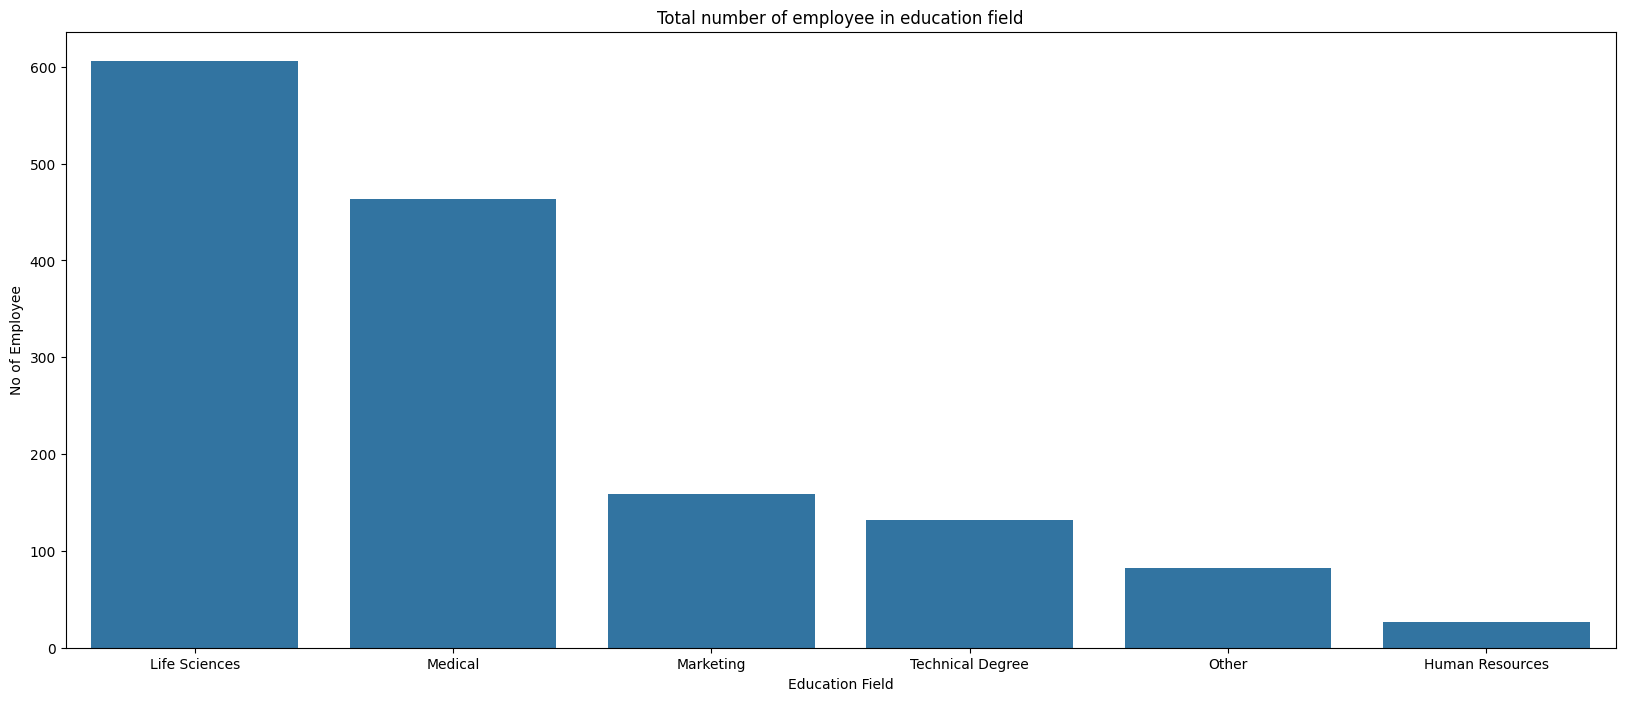

In [17]:
plt.figure(figsize=(20,8))
plt.title('Total number of employee in education field')
sns.barplot(x='EducationField',y='count',data=edu)
plt.xlabel('Education Field')
plt.ylabel('No of Employee')

In [18]:
top_edu=edu.sort_values(by='count',ascending=False)
top_edu

,EducationField,count
0,Life Sciences,606
1,Medical,464
2,Marketing,159
3,Technical Degree,132
4,Other,82
5,Human Resources,27


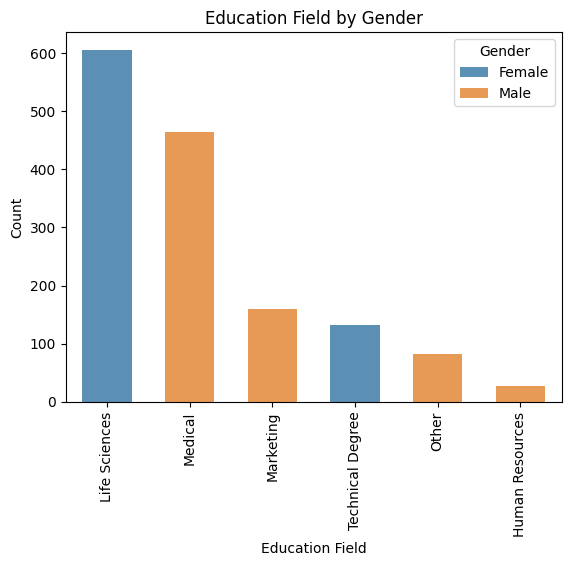

In [19]:
sns.barplot(data=top_edu,x='EducationField',y='count',hue=df['Gender'],alpha=0.8,width=0.6)
plt.ylabel('Count')
plt.xlabel('Education Field')
plt.title('Education Field by Gender')
plt.xticks(rotation=90)
plt.show()

In [20]:
bt = df["BusinessTravel"].str.split(", ")
bt

0           [Travel_Rarely]
1       [Travel_Frequently]
2           [Travel_Rarely]
3       [Travel_Frequently]
4           [Travel_Rarely]
               ...         
1465    [Travel_Frequently]
1466        [Travel_Rarely]
1467        [Travel_Rarely]
1468    [Travel_Frequently]
1469        [Travel_Rarely]
Name: BusinessTravel, Length: 1470, dtype: object

In [21]:
from collections import Counter
counter = Counter()
for i in bt:
    counter.update(i)

In [22]:
bt_10 = counter.most_common(10)[::-1]

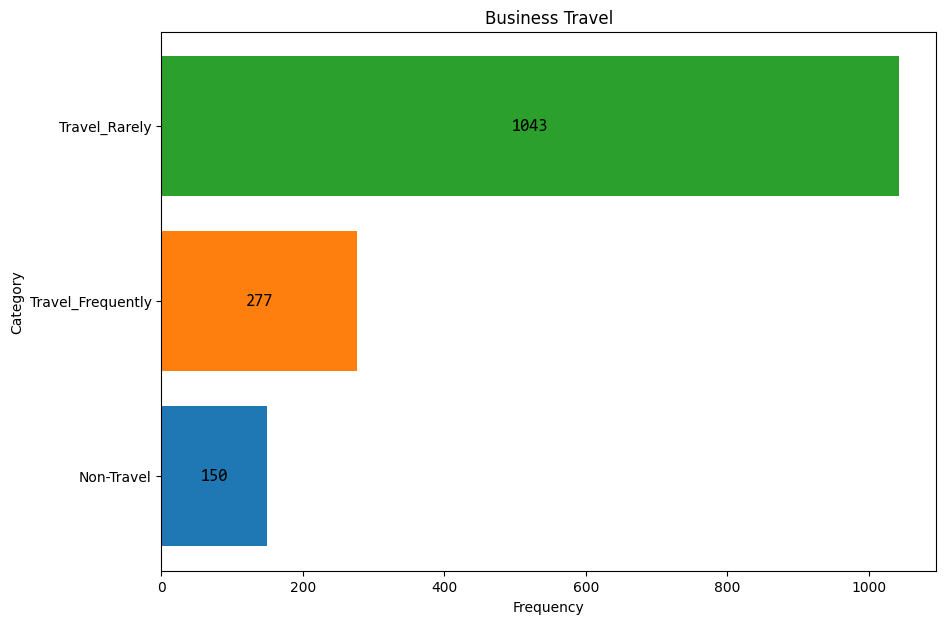

In [23]:
plt.figure(figsize=(10, 7))
for i in bt_10:
    fig = plt.barh(i[0], i[1])
    plt.bar_label( fig, label_type='center', size="12", family="consolas")  
    
plt.title("Business Travel")    
plt.xlabel("Frequency")    
plt.ylabel("Category")    
plt.show()

<Axes: >

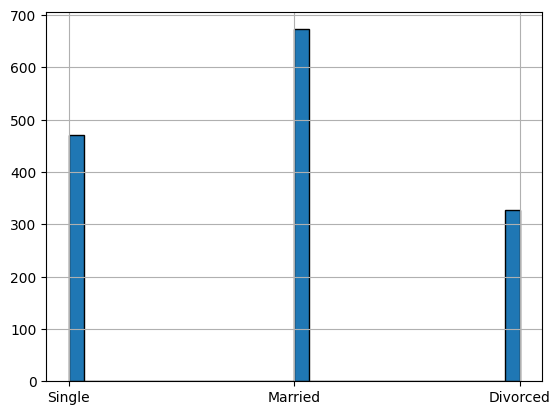

In [24]:
df['MaritalStatus'].hist(bins=30, edgecolor='black')

<Axes: xlabel='Education', ylabel='OverTime'>

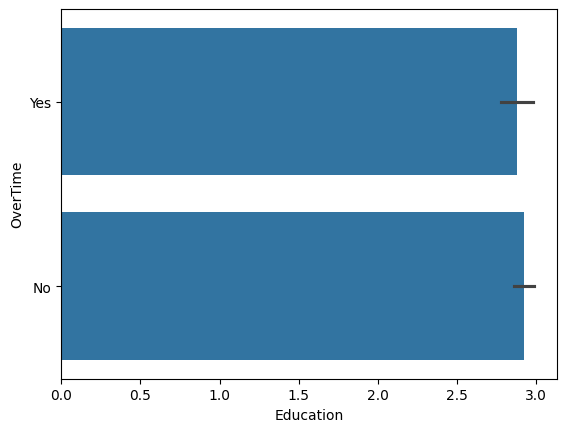

In [25]:
sns.barplot(x='Education',y='OverTime', data=df, estimator=np.mean)

<Axes: xlabel='Education', ylabel='OverTime'>

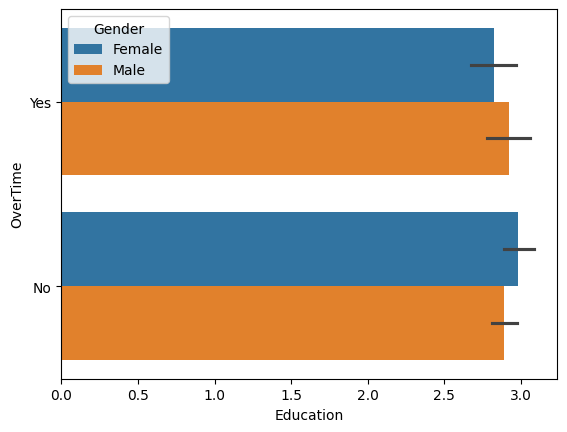

In [42]:
sns.barplot(x='Education',y='OverTime', hue='Gender', data=df, estimator=np.mean)

# Logistic Regression

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [35]:
X = df[['JobInvolvement', 'JobLevel', 'JobSatisfaction','PerformanceRating', 'YearsInCurrentRole',  'TotalWorkingYears']]
y = df['OverTime']

In [36]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [37]:
# Initialize the Logistic Regression model
logistic_regression = LogisticRegression()

In [38]:
logistic_regression.fit(X_train, y_train)

LogisticRegression()

In [39]:
# Make predictions on the testing data
y_pred = logistic_regression.predict(X_test)

In [40]:
# Evaluate the model's accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.7380952380952381
